In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/SMSSpamCollection",
               sep='\t',
               header=None,
               names=['label','message'])

In [3]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.tail()

,label,message
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [5]:
df.shape

(5572, 2)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [7]:
df.describe()

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


###Observation :
1)Total messages : 5572

2)Two types of labels - Ham and spam.
Ham messages are more frequent in the current dataset

3)5169 unique messages and 403 duplicated messages

In [8]:
df.isnull().sum()

,0
label,0
message,0


In [9]:
df.duplicated().sum()

np.int64(403)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.shape

(5169, 2)

We dropped 403 duplicate messages and now we 5169 messages

In [12]:
df['label'].value_counts()

,count
label,
ham,4516
spam,653


In [13]:
df['label'].value_counts(normalize=True)*100

,proportion
label,
ham,87.366996
spam,12.633004


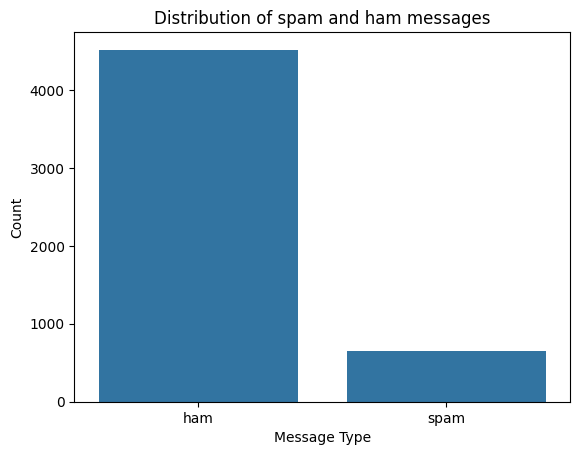

In [14]:
sns.countplot(data=df,x='label')
plt.title('Distribution of spam and ham messages')
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.show()

In [15]:
df['message_length']=df['message'].apply(len)

In [16]:
df.head()

,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [17]:
df['word_count']=df['message'].apply(lambda x:len(x.split()))

In [18]:
df.head()

,label,message,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


In [19]:
df.groupby('label')['message_length'].mean()

,message_length
label,
ham,70.905890
spam,137.704441


 Observation 4: Message Length Analysis
- Average ham message length: 70.90 characters.
- Average spam message length: 137.70 characters.
- Spam messages are longer on average than ham messages.
- Message length may be a useful exploratory feature for classification.

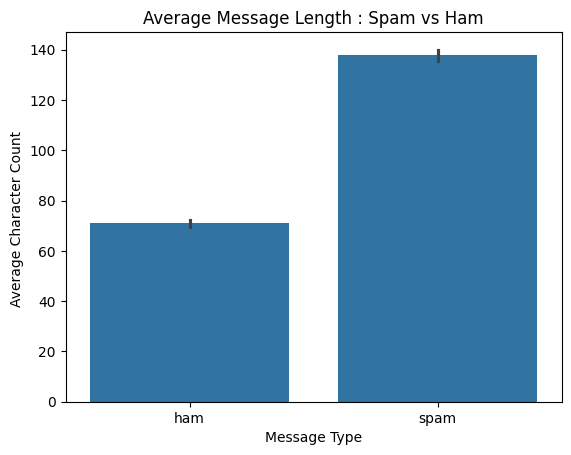

In [20]:
sns.barplot(data=df,x='label',y='message_length')
plt.title('Average Message Length : Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Average Character Count ')
plt.show()

In [21]:
df.groupby('label')['word_count'].mean()

,word_count
label,
ham,14.239814
spam,23.739663


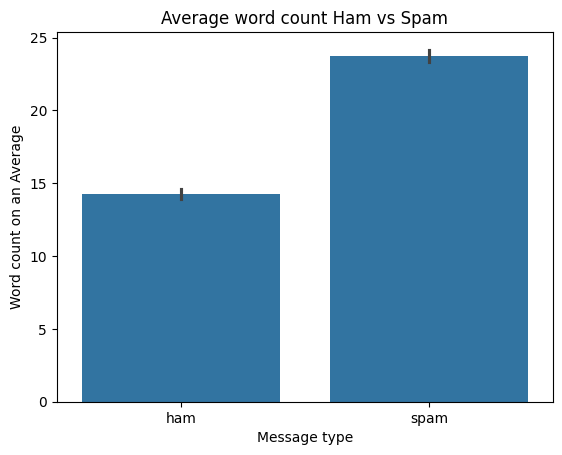

In [22]:
sns.barplot(data=df,x='label',y='word_count')
plt.title('Average word count Ham vs Spam')
plt.xlabel('Message type')
plt.ylabel('Word count on an Average')
plt.show()

Observation 5) Word Count Analysis


*   On an avg the ham messages have around 14 words

*   On an avg the spam messages have around 24 words

*   Spam messages have higher word count than ham messages
*   Word count may be useful feature for classification of messages as ham or spam






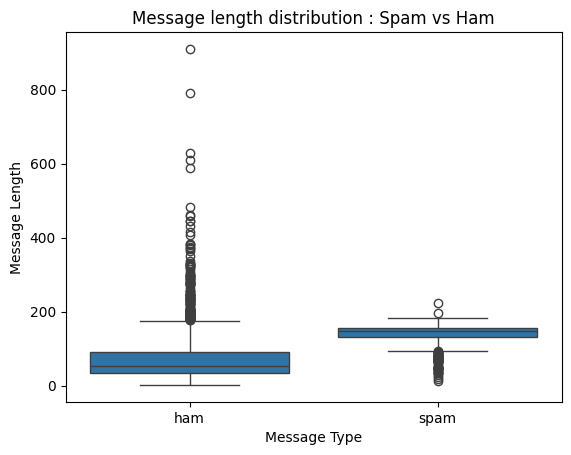

In [23]:
sns.boxplot(data=df,x='label',y='message_length')
plt.title('Message length distribution : Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Message Length')
plt.show()

Observation 6: Message Length Distribution (Box Plot)
1. Spam messages have a higher median character count than ham messages.
2. Ham messages show a wider interquartile range (IQR), indicating greater variability in the middle 50% of message lengths.
3. Ham messages contain numerous upper outliers, indicating the presence of unusually long legitimate messages.
4. Spam messages also contain outliers, particularly on the lower side.
5. Message length distributions differ between spam and ham messages, suggesting that message length may be useful for classification.

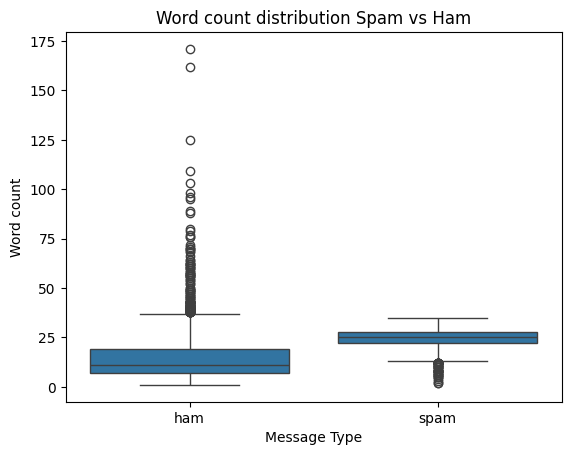

In [24]:
sns.boxplot(data=df,x='label',y='word_count')
plt.title('Word count distribution Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Word count')
plt.show()

Observation 7: Word Count Distribution (Box Plot)
1. Spam messages have a higher median word count than ham messages.
2. Ham messages exhibit a wider interquartile range, indicating greater variability in word counts.
3. Ham messages contain numerous upper outliers, representing unusually long messages.
4. Spam messages contain several lower outliers, representing unusually short messages.
5. Word count distribution differs between spam and ham messages, suggesting that it may be a useful feature for classification.

In [25]:
X=df['message']
y=df['label']

### Train, Validation and Test Split

The dataset is divided into three subsets:

1. **Training Set (64%)**: Used to train the Logistic Regression model.
2. **Validation Set (16%)**: Used to evaluate the model and select the optimal classification threshold.
3. **Test Set (20%)**: Used only for the final evaluation of the selected model.

The dataset is split using `train_test_split()` with `stratify=y` to maintain the original proportion of ham and spam messages in each subset.

A fixed `random_state=42` is used to ensure reproducibility.

In [26]:
from sklearn.model_selection import train_test_split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=y_train_val
)

In [28]:
print(X_train_val.shape)
print(X_test.shape)
print(y_train_val.shape)
print(y_test.shape)

(4135,)
(1034,)
(4135,)
(1034,)


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [30]:
tfidf=TfidfVectorizer()

In [31]:
X_train_tfidf=tfidf.fit_transform(X_train)

In [32]:
X_val_tfidf = tfidf.transform(X_val)

In [33]:
X_train_tfidf.shape

(3308, 6710)

3308 - Training Messages

6710 - Unique Vocabulary features learned by TF-IDF

In [34]:
X_test_tfidf=tfidf.transform(X_test)

In [35]:
X_test_tfidf.shape

(1034, 6710)

1034 - Testing Messages

6710 - Unique Vocab fetures learned by TF-IDF

In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
model = LogisticRegression(max_iter=1000)

In [38]:
model.fit(X_train_tfidf,y_train)

LogisticRegression(max_iter=1000)

### 8. Baseline Model Evaluation (Default Threshold = 0.5)

After training the Logistic Regression model, its initial performance is evaluated using the default classification threshold of 0.5.

The validation dataset is used to evaluate the model through the classification report and confusion matrix.

This baseline evaluation helps identify the model's initial performance and areas where improvement is required.

In [39]:
from sklearn.metrics import classification_report, confusion_matrix

# Original default threshold
y_val_pred_default = model.predict(X_val_tfidf)

print("Classification Report (Default Threshold 0.5):")
print(classification_report(y_val, y_val_pred_default))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_default))

Classification Report (Default Threshold 0.5):
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       723
        spam       0.99      0.65      0.79       104

    accuracy                           0.96       827
   macro avg       0.97      0.83      0.88       827
weighted avg       0.96      0.96      0.95       827

Confusion Matrix:
[[722   1]
 [ 36  68]]


In [40]:
y_val_probabilities = model.predict_proba(X_val_tfidf)[:, 1]

### 9. Threshold Tuning

The baseline model uses a default classification threshold of 0.5. However, the initial evaluation shows that the model misses some actual spam messages.

To improve spam detection, different classification thresholds (0.3, 0.4 and 0.5) are tested using the validation dataset.

Lowering the threshold may increase spam recall, but it can also increase false positives. Therefore, precision, recall and F1-score are compared to select a suitable threshold.

In [41]:
from sklearn.metrics import classification_report

for threshold in [0.3, 0.4, 0.5]:

    y_val_pred = np.where(
        y_val_probabilities >= threshold,
        'spam',
        'ham'
    )

    print(f"\nThreshold: {threshold}")
    print(classification_report(y_val, y_val_pred))


Threshold: 0.3
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98       723
        spam       0.96      0.83      0.89       104

    accuracy                           0.97       827
   macro avg       0.97      0.91      0.94       827
weighted avg       0.97      0.97      0.97       827


Threshold: 0.4
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       723
        spam       0.98      0.77      0.86       104

    accuracy                           0.97       827
   macro avg       0.97      0.88      0.92       827
weighted avg       0.97      0.97      0.97       827


Threshold: 0.5
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       723
        spam       0.99      0.65      0.79       104

    accuracy                           0.96       827
   macro avg       0.97      0.83      0.88       827
weighted avg       0.96   

### 10. Final Model Evaluation on Test Data

After selecting the classification threshold of 0.3 using the validation dataset, the model is evaluated on the separate test dataset.

The test dataset is used only for final evaluation to assess how well the model performs on unseen SMS messages.

The performance is measured using accuracy, precision, recall, F1-score and the confusion matrix.

In [42]:
y_test_probabilities = model.predict_proba(X_test_tfidf)[:, 1]

In [43]:
threshold = 0.3

y_test_pred = np.where(
    y_test_probabilities >= threshold,
    'spam',
    'ham'
)

In [44]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Final Model Evaluation (Threshold = 0.3)")

print("\nAccuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Final Model Evaluation (Threshold = 0.3)

Accuracy: 0.9748549323017408

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.94      0.85      0.90       131

    accuracy                           0.97      1034
   macro avg       0.96      0.92      0.94      1034
weighted avg       0.97      0.97      0.97      1034


Confusion Matrix:
[[896   7]
 [ 19 112]]


### Observations and Results

The Logistic Regression model achieved an accuracy of approximately 97.49% on the test dataset using a classification threshold of 0.3.

The model correctly classified 112 spam messages out of 131 actual spam messages, achieving a spam recall of approximately 85%.

The confusion matrix shows:
- 896 ham messages were correctly classified.
- 112 spam messages were correctly classified.
- 7 ham messages were incorrectly classified as spam.
- 19 spam messages were incorrectly classified as ham.

The validation results showed that lowering the classification threshold from 0.5 to 0.3 increased spam recall from 65% to 83%, while maintaining a spam precision of 96%. The selected threshold was then evaluated on the separate test dataset, where the model achieved 97.49% accuracy and 85% spam recall.

### 11. Testing with Custom SMS Messages

To check the model's practical performance, custom SMS messages are provided as input.

The trained TF-IDF vectorizer transforms these messages into numerical features, and the Logistic Regression model predicts whether each message is spam or ham.

The selected classification threshold of 0.3 is used to make the final predictions.

In [45]:
message = input("Enter an SMS message: ")

message_tfidf = tfidf.transform([message])

spam_probability = model.predict_proba(message_tfidf)[0][1]

threshold = 0.3

prediction = "Spam" if spam_probability >= threshold else "Ham"

print("\n---------- SMS Classification Result ----------")
print("Entered Message:", message)
print("Prediction:", prediction)
print("Spam Probability:", round(spam_probability * 100, 2), "%")
print("------------------------------------------------")

Enter an SMS message: Hello! Can we talk ?

---------- SMS Classification Result ----------
Entered Message: Hello! Can we talk ?
Prediction: Ham
Spam Probability: 3.9 %
------------------------------------------------


## 12. Conclusion and Limitations

### Conclusion

In this project, a machine learning model was developed to classify SMS messages as Spam or Ham using TF-IDF and Logistic Regression.

The dataset was cleaned by removing duplicate messages, followed by exploratory data analysis to understand the distribution and characteristics of the messages.

TF-IDF was used to convert text messages into numerical features, and Logistic Regression was trained for classification.

The classification threshold was tuned using the validation dataset, and the selected threshold of 0.3 was evaluated on the separate test dataset.

The final model achieved:
- **Accuracy:** 97.49%
- **Spam Precision:** 94%
- **Spam Recall:** 85%
- **Spam F1-score:** 90%

The project demonstrates how text preprocessing, feature extraction, model training, and threshold tuning can be combined to build an SMS spam detection system.

### Limitations

- The model may misclassify some messages, as shown by the false positives and false negatives in the test results.
- Its predictions depend on the words and patterns learned from the training dataset.
- It may not perform equally well on new messages containing unfamiliar words, expressions, or spam patterns.
- The model should be treated as a learning prototype rather than a fully reliable spam filtering system.